# IT25100429 — Member 5: EBM individual contribution

This notebook implements and compares six EBM varieties, documents tuning and a standardization sensitivity experiment, and supplies evidence for the individual assessment. Historical default-only outputs remain separate. No final holdout evaluation or group winner selection is performed.

## Model suitability
`Resigned` is binary and the data contain four nominal and thirteen numerical/ordinal predictors. InterpretML's ExplainableBoostingClassifier handles these types directly and learns nonlinear additive feature effects plus optional interactions. It is suitable for examining predictive associations while retaining readable explanations. A feature effect is not a causal reason for resignation. Approximately 10% positive prevalence makes raw accuracy inadequate.

## Implementation and parameters
The helper uses pandas, NumPy, scikit-learn and InterpretML. `fit` trains, `predict_proba` returns positive-class probabilities, `train_test_split` creates inner validation, and `StandardScaler` fits only on the appropriate training subset. All 17 shared predictors remain present; categorical fields use native nominal types.

Learning rate controls update size; maximum leaves controls tree complexity; minimum samples per leaf regularizes partitions; interactions controls pairwise terms. Fixed settings: 256 main-effect bins, 32 interaction bins, 5,000 maximum rounds, 100 early-stopping rounds, 15% internal validation, eight outer bags, seed 42, two workers. EBM's internal early stopping optimizes log loss; candidate selection uses external inner Average Precision. Internal EBM bagging is distinct from the project's five outer CV folds.

## Bounded manual grid and preprocessing
Three parameter settings are each trained with raw and standardized numerical values: six varieties. E01: learning rate .015, two leaves, minimum leaf size 10, no interactions. E02: .03, two leaves, minimum leaf size 4, five interactions. E03: .005, three leaves, minimum leaf size 2, ten interactions.

Scaling tests the standardization contribution without assuming a benefit: bin-based EBM commonly changes little under linear rescaling. Nominal fields are never standardized. Primary nested selection considers the three raw variants, as required by the shared feature representation; scaled variants are a separate sensitivity comparison.

## Validation and tuning boundaries
For each saved outer fold, the other 64,000 development records are split into 54,400 inner-training and 9,600 inner-validation records. Six candidates are fitted and measured on inner validation, then separately refitted on outer training and evaluated on the 16,000 outer-validation records. Primary selection uses inner AP only. Candidates within a predeclared .001 absolute AP of the best are treated as practically equivalent; fewer interactions, fewer leaves and stable candidate ID break ties. This margin is a decision rule, not a statistical significance test.

The experiment performs 30 inner fits and 30 outer refits. Each fixed variety and the nested selection procedure receive 80,000 OOF predictions. Fixed-variety comparisons are descriptive; choosing a winner by their outer scores would introduce selection optimism. The nested procedure supplies the primary evaluation. Final global refit and holdout remain reserved until group comparison and freeze.


## Individual preprocessing and parameter evidence

The table below is generated from `configs/models/ebm.yaml`. E02 uses two leaves and E03 uses three. Each raw setting has a matched standardized variety, with scaling fitted on training rows only. Inner AP selects among raw candidates; standardized pairs are sensitivity evidence. Pooled OOF AP is the primary group ranking metric; mean fold AP and its spread describe stability.


In [9]:
import sys
print(sys.executable)

/Users/hirukaliyanage/Documents/ChatGPT/Employee Resignation/.venv/bin/python


In [10]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
from IPython.display import display
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/feature_contract.yaml").exists())
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
from src.models.ebm_experiments import CONFIG, CANDIDATES, run_experiments
pd.set_option("display.max_columns", None)
RUN_EBM_TRAINING = False
CANONICAL_RESULTS_DIR = PROJECT_ROOT / CONFIG["canonical_results"]["directory"]
# Parameter explanations come directly from the candidate config, including leaf counts.
parameter_table = pd.DataFrame(CANDIDATES)
display(parameter_table[["candidate_id", "preprocessing", "learning_rate", "max_leaves", "min_samples_leaf", "interactions"]])


,candidate_id,preprocessing,learning_rate,max_leaves,min_samples_leaf,interactions
0,E01_raw,raw,0.015,2,10,0
1,E01_standardized,standardized,0.015,2,10,0
2,E02_raw,raw,0.030,2,4,5
3,E02_standardized,standardized,0.030,2,4,5
4,E03_raw,raw,0.005,3,2,10
5,E03_standardized,standardized,0.005,3,2,10


## Saved evidence review (default)

`RUN_EBM_TRAINING = False` loads and validates the completed canonical development results. Run All performs no model fitting or result export in this mode. The tables and figures below are recorded evidence; serialized models may be unavailable in this checkout.

To deliberately repeat the full workflow, change the flag in the preceding setup cell to `True`, then restart and run all. Every new run writes to `results/models/ebm/reruns/<UTC timestamp>/`; saved canonical and historical evidence stays in place. Adopting a new run for group evaluation requires a separate explicit registry update.


Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,0.099,0.495976,0.0,0.0,0.0,0.5,0.8999,0.090109,71992,0,8008,0,0,0.0


,fold,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,1,0.096220,0.487749,0.0,0.0,0.0,0.5,0.899937,0.090123,14399,0,1601,0,0,0.0
1,2,0.101301,0.500770,0.0,0.0,0.0,0.5,0.899937,0.090089,14399,0,1601,0,0,0.0
2,3,0.101141,0.500416,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
3,4,0.099062,0.495844,0.0,0.0,0.0,0.5,0.899875,0.090119,14398,0,1602,0,0,0.0
4,5,0.100064,0.498062,0.0,0.0,0.0,0.5,0.899875,0.090114,14398,0,1602,0,0,0.0


Recorded six-variety preprocessing comparison


,setting,learning_rate,max_leaves,min_samples_leaf,interactions,preprocessing,candidate_id,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,cv_mean_ap,cv_std_ap
0,E01,0.015,2,10,0,raw,E01_raw,0.098714,0.495909,0.0,0.0,0.0,0.5,0.8999,0.090093,71992,0,8008,0,0,0.0,0.099570,0.002101
1,E01,0.015,2,10,0,standardized,E01_standardized,0.098714,0.495909,0.0,0.0,0.0,0.5,0.8999,0.090093,71992,0,8008,0,0,0.0,0.099570,0.002101
2,E02,0.030,2,4,5,raw,E02_raw,0.097735,0.492520,0.0,0.0,0.0,0.5,0.8999,0.090129,71992,0,8008,0,0,0.0,0.097884,0.002106
3,E02,0.030,2,4,5,standardized,E02_standardized,0.097735,0.492520,0.0,0.0,0.0,0.5,0.8999,0.090129,71992,0,8008,0,0,0.0,0.097884,0.002106
4,E03,0.005,3,2,10,raw,E03_raw,0.098626,0.494396,0.0,0.0,0.0,0.5,0.8999,0.090120,71992,0,8008,0,0,0.0,0.099097,0.001271
5,E03,0.005,3,2,10,standardized,E03_standardized,0.098626,0.494396,0.0,0.0,0.0,0.5,0.8999,0.090120,71992,0,8008,0,0,0.0,0.099097,0.001271


Recorded inner selection evidence


,setting,learning_rate,max_leaves,min_samples_leaf,interactions,preprocessing,candidate_id,outer_fold,inner_ap,inner_train_rows,inner_validation_rows
0,E01,0.015,2,10,0,raw,E01_raw,1,0.102646,54400,9600
1,E01,0.015,2,10,0,standardized,E01_standardized,1,0.102646,54400,9600
2,E02,0.030,2,4,5,raw,E02_raw,1,0.103665,54400,9600
3,E02,0.030,2,4,5,standardized,E02_standardized,1,0.103665,54400,9600
4,E03,0.005,3,2,10,raw,E03_raw,1,0.101975,54400,9600
5,E03,0.005,3,2,10,standardized,E03_standardized,1,0.101975,54400,9600
6,E01,0.015,2,10,0,raw,E01_raw,2,0.096931,54400,9600
7,E01,0.015,2,10,0,standardized,E01_standardized,2,0.096931,54400,9600
8,E02,0.030,2,4,5,raw,E02_raw,2,0.100460,54400,9600
9,E02,0.030,2,4,5,standardized,E02_standardized,2,0.100460,54400,9600


Recorded feature importance (outer fold 1 explanation)


,term,importance
0,Monthly_Salary & Projects_Handled,0.014744
1,Remote_Work_Frequency & Training_Hours,0.013925
2,Overtime_Hours & Team_Size,0.013871
3,Performance_Score & Training_Hours,0.012754
4,Job_Title,0.012400
5,Department,0.012267
6,Remote_Work_Frequency,0.011088
7,Years_At_Company & Work_Hours_Per_Week,0.010090
8,Performance_Score,0.006701
9,Training_Hours,0.005895


**Recorded development conclusion:** pooled AP 0.099000 versus prevalence 0.100100, ROC-AUC 0.495976, Brier 0.090109. Discrimination remains near no-skill. Pooled AP is the primary group ranking metric; mean fold AP describes stability. Threshold and importance diagnostics are descriptive, and the formal holdout is excluded.

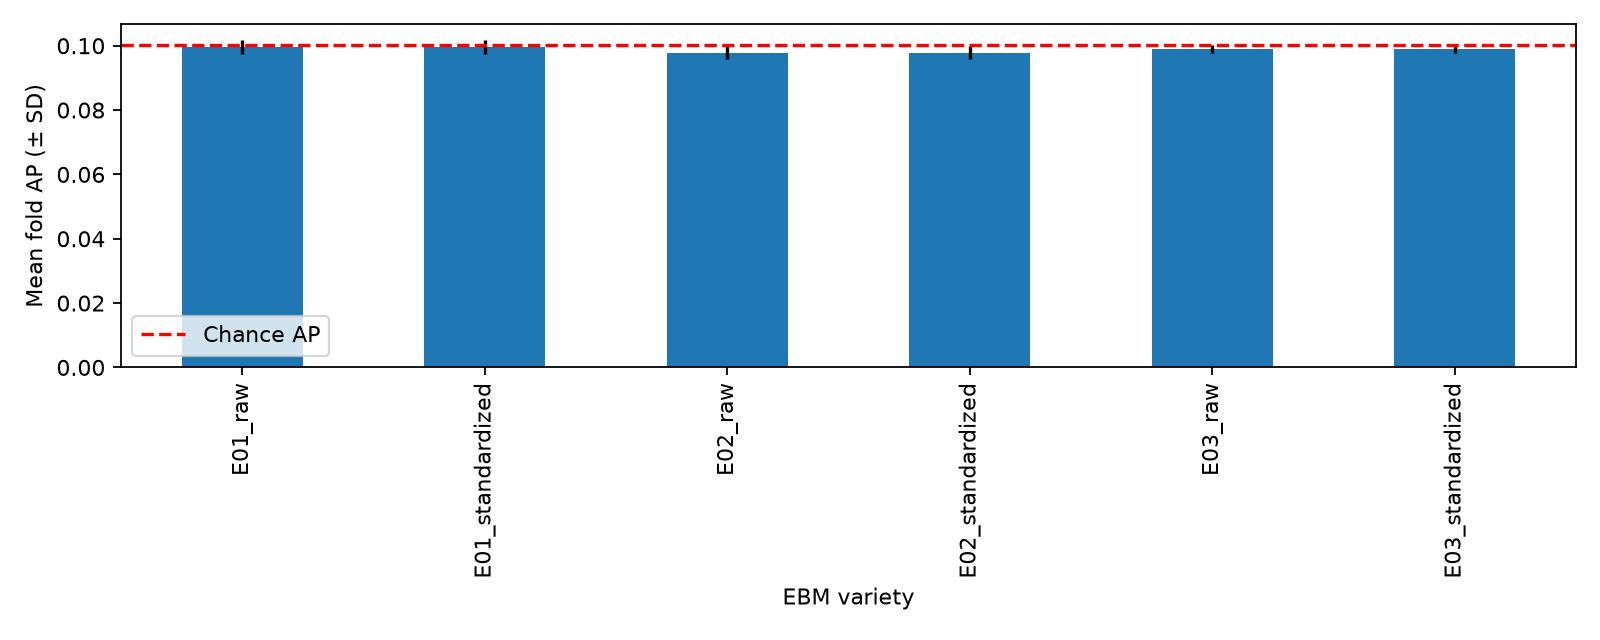

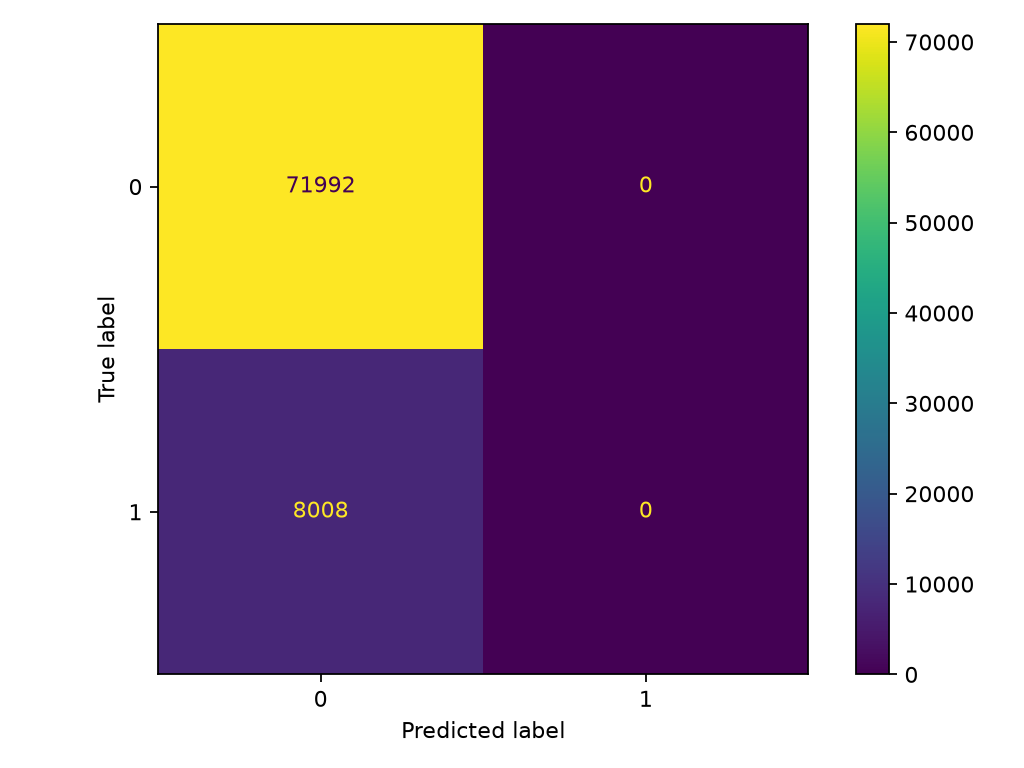

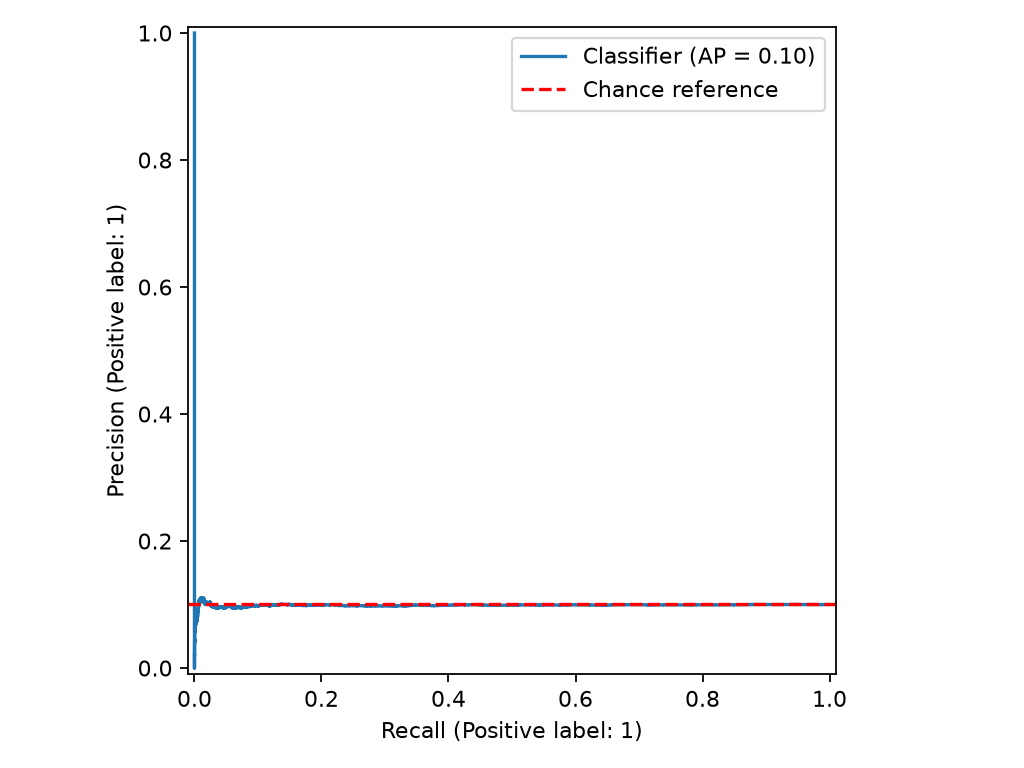

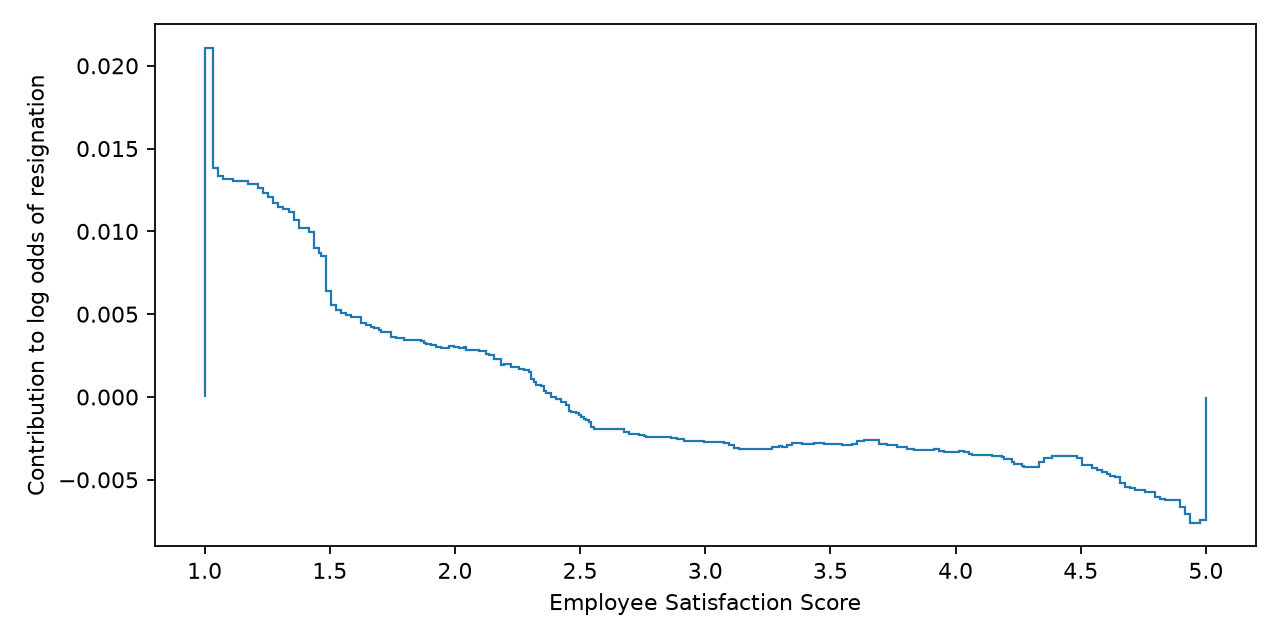

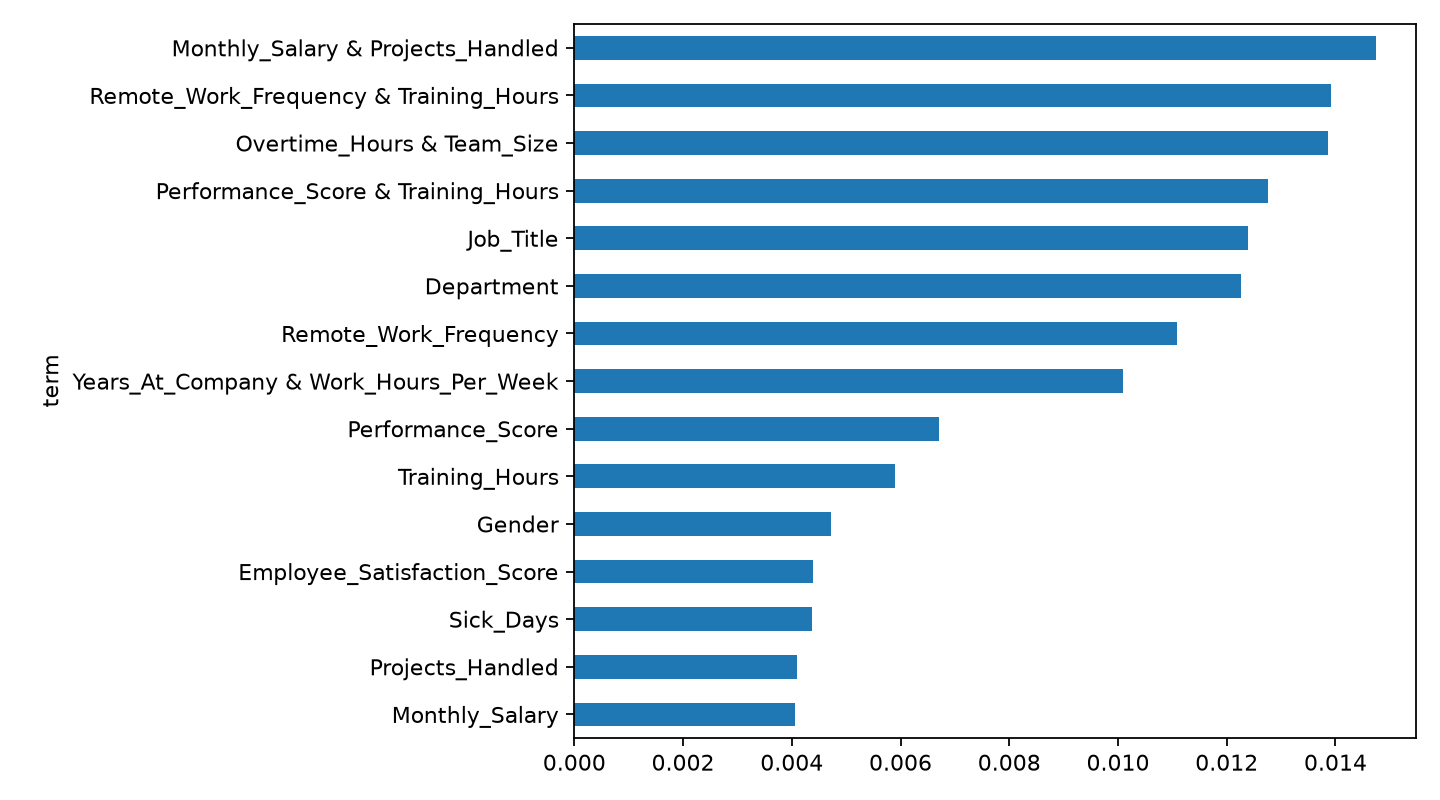

Saved evidence validated. No training, serialization or exports performed.


In [11]:
if not RUN_EBM_TRAINING:
    from src.evaluation.inputs import load_saved_model_evidence
    from src.evaluation.metrics import calculate_binary_metrics
    from IPython.display import Image, Markdown
    saved_oof, saved_folds, saved_summary = load_saved_model_evidence(
        PROJECT_ROOT, 'EBM', CANONICAL_RESULTS_DIR,
        summary_file='summary_metrics.json',
    )
    saved_pooled = calculate_binary_metrics(saved_oof.y_true, saved_oof.y_probability)
    display(pd.DataFrame([saved_pooled]))
    display(saved_folds)
    print('Recorded six-variety preprocessing comparison')
    display(pd.read_csv(CANONICAL_RESULTS_DIR / 'candidate_comparison.csv'))
    print('Recorded inner selection evidence')
    display(pd.read_csv(CANONICAL_RESULTS_DIR / 'inner_selection.csv'))
    print('Recorded feature importance (outer fold 1 explanation)')
    display(pd.read_csv(CANONICAL_RESULTS_DIR / 'term_importances.csv'))
    display(Markdown(
        f"**Recorded development conclusion:** pooled AP {saved_pooled['average_precision']:.6f} "
        f"versus prevalence {saved_oof.y_true.mean():.6f}, ROC-AUC {saved_pooled['roc_auc']:.6f}, "
        f"Brier {saved_pooled['brier_score']:.6f}. Discrimination remains near no-skill. "
        "Pooled AP is the primary group ranking metric; mean fold AP describes stability. "
        "Threshold and importance diagnostics are descriptive, and the formal holdout is excluded."
    ))
    for filename in ['candidate_comparison.png', 'nested_confusion_matrix.png', 'nested_pr_curve.png', 'satisfaction_shape.png', 'term_importance.png']:
        image_path = CANONICAL_RESULTS_DIR / filename
        if image_path.is_file():
            display(Image(filename=str(image_path)))
        else:
            print(f"Recorded figure unavailable in this checkout: {filename}")

    print("Saved evidence validated. No training, serialization or exports performed.")


## Optional training workflow

The remaining cells describe and implement the recorded protocol. They execute only when training is enabled. Their original training settings are retained; the saved review above does not reconstruct fitted adapters or claim that serialization was checked again.


## Deliberate nested experiment

With training enabled, the next cell performs 30 inner candidate fits and 30 outer refits, writing a new run directory. The explanation section performs one additional fit. Default saved review performs none of these fits.


In [12]:
if RUN_EBM_TRAINING:
    data, comparison, oof, metrics, output_dir = run_experiments(PROJECT_ROOT)
    display(comparison)
    display(pd.DataFrame([metrics]))

## Compare parameter varieties and standardization

### Candidate comparison - vertical bar chart with error bars
Each bar shows the mean outer-fold Average Precision (AP) for one of the six EBM varieties. The error bars show the standard deviation across folds; they are not confidence intervals. The red dashed line marks the positive-class prevalence reference. Raw and standardized pairs had identical predictions and performance in the saved experiment. Results remained near chance. This fixed-variety comparison is descriptive; inner validation selects candidates for the primary nested evaluation.


In [13]:
if RUN_EBM_TRAINING:
    paired = comparison.pivot(index="setting", columns="preprocessing", values="average_precision")
    paired["scaled_minus_raw_ap"] = paired["standardized"] - paired["raw"]
    display(paired)
    display(pd.read_csv(output_dir / "inner_selection.csv"))
    display(oof.groupby("cv_fold").selected_candidate.first().rename("inner_selected_candidate").to_frame())
    comparison.plot.bar(x="candidate_id", y="cv_mean_ap", yerr="cv_std_ap", legend=False, figsize=(10,4))
    chance_line = plt.axhline(data.Resigned.mean(), color="red", linestyle="--", label="Chance AP")
    plt.ylabel("Mean fold AP (± SD)"); plt.xlabel("EBM variety")
    plt.legend(handles=[chance_line]); plt.tight_layout(); plt.savefig(output_dir / "candidate_comparison.png", dpi=160); plt.show()

## Primary nested evaluation and classification behavior

### Precision-Recall curve - curve / line plot
The horizontal axis shows recall and the vertical axis shows precision as the decision threshold changes. It illustrates the tradeoff between detecting actual resignations and making correct resignation alerts. The dashed prevalence line is a reference for the imbalanced positive class. The saved nested AP of approximately 0.099 indicates performance near that reference.

### Confusion matrix - 2 x 2 colour-coded matrix
The rows show actual classes and the columns show predicted classes at the fixed 0.50 threshold. Class 0 means stayed; class 1 means resigned. The saved result has TN = 71,992, FP = 0, FN = 8,008 and TP = 0. The model predicted every employee as stayed, explaining its 89.99% accuracy and zero resignation recall.


In [14]:
if RUN_EBM_TRAINING:
    PrecisionRecallDisplay.from_predictions(oof.y_true, oof.y_probability)
    plt.axhline(data.Resigned.mean(), color="red", linestyle="--", label="Chance reference")
    plt.legend(); plt.tight_layout(); plt.savefig(output_dir / "nested_pr_curve.png", dpi=160); plt.show()
    ConfusionMatrixDisplay.from_predictions(oof.y_true, (oof.y_probability >= .5).astype(int))
    plt.tight_layout(); plt.savefig(output_dir / "nested_confusion_matrix.png", dpi=160); plt.show()
    print(f"Nested AP={metrics['average_precision']:.6f}; ROC-AUC={metrics['roc_auc']:.6f}; recall={metrics['recall']:.6f}; F1={metrics['f1']:.6f}")
    print("A majority-class model achieves about 90% accuracy while detecting no resignations. Interpret ranking and minority-class metrics first.")

## Conclusions and limitations
The following cell generates a conclusion from actual outputs. Small numerical differences should not be called meaningful improvements without additional uncertainty analysis. The bounded search does not exhaust all EBM configurations; a single inner split can produce unstable winners. Standardization may change rounding/binning while providing little predictive benefit. Internal log-loss early stopping differs from the AP selection criterion. The fixed .50 threshold can suppress minority-class predictions; threshold selection and calibration belong to later development-only evaluation. More useful improvements include repeated inner validation, probability calibration, carefully assessed class weighting and better longitudinal predictors. Any further experiment must preserve the frozen holdout boundary.

The dataset's observed feature regularities and near-chance historical results limit claims about real HR decisions. Importance graphs describe the fitted model even when predictive signal is weak. They do not establish causal effects or fairness.


In [15]:
if RUN_EBM_TRAINING:
    lift = metrics["average_precision"] - data.Resigned.mean()
    conclusion = (f"Primary nested EBM AP {metrics['average_precision']:.6f} (difference from prevalence {lift:+.6f}), "
                  f"ROC-AUC {metrics['roc_auc']:.6f}, Brier {metrics['brier_score']:.6f}. "
                  f"Largest absolute scaling AP difference across paired varieties: {paired.scaled_minus_raw_ap.abs().max():.6f}. "
                  "These development results require comparison against chance references and fold variability; "
                  "they do not establish deployment readiness. Six varieties were evaluated; final group model selection and holdout remain pending.")
    print(conclusion)
    (output_dir / "conclusion.txt").write_text(conclusion)

## Explain the selected model
For demonstration, refit the fold-1 selected configuration on its 64,000 training records only. This explanation model is not a frozen group model. Global term importance measures average absolute contribution to log odds; the feature-shape plot shows the fitted association, not causation.

### Term importance - horizontal bar chart
Bars show the average absolute contribution magnitude of individual features or interaction terms in the fitted explanation model. Longer bars indicate larger contributions on the log-odds scale. Importance explains model behaviour; it does not establish causation, direction of effect or useful predictive performance.

### Employee satisfaction effect - step plot / feature-effect plot
The horizontal axis shows Employee_Satisfaction_Score and the vertical axis shows its contribution to resignation log-odds. Positive contributions increase the model score, while negative contributions decrease it relative to a zero contribution. The steps reflect the learned bins. This is a fitted association, not a causal effect or a direct probability plot.


In [16]:
if RUN_EBM_TRAINING:
    from src.models.ebm_experiments import fit_candidate
    import yaml
    contract = yaml.safe_load((PROJECT_ROOT / "configs/feature_contract.yaml").read_text())
    features = contract["primary_model_features"]
    categories = [f["name"] for f in contract["categorical_features"]]
    selected_id = oof.loc[oof.cv_fold == 1, "selected_candidate"].iloc[0]
    candidate = next(c for c in CANDIDATES if c["candidate_id"] == selected_id)
    training = data.loc[data.cv_fold != 1]
    explanation_model, _, _ = fit_candidate(training[features], training.Resigned, candidate, categories)
    explanation = explanation_model.explain_global()
    importance = pd.DataFrame({"term": explanation.data()["names"], "importance": explanation.data()["scores"]}).sort_values("importance", ascending=False)
    display(importance.head(10))
    importance.head(15).sort_values("importance").plot.barh(x="term", y="importance", legend=False, figsize=(9,5))
    plt.tight_layout(); plt.savefig(output_dir / "term_importance.png", dpi=160); plt.show()
    term_index = next(i for i,t in enumerate(explanation_model.term_features_) if len(t) == 1 and features[t[0]] == "Employee_Satisfaction_Score")
    shape = explanation.data(term_index)
    plt.figure(figsize=(8,4)); plt.stairs(shape["scores"], shape["names"])
    plt.xlabel("Employee Satisfaction Score"); plt.ylabel("Contribution to log odds of resignation")
    plt.tight_layout(); plt.savefig(output_dir / "satisfaction_shape.png", dpi=160); plt.show()
    importance.to_csv(output_dir / "term_importances.csv", index=False)


## Demonstration guide and individual requirement evidence
1. Explain EBM's additive log-odds feature effects and optional pairwise interactions, and why it suits mixed HR predictors.
2. Show the six candidate settings and identify what changes between each pair and parameter setting.
3. Open `src/models/ebm_experiments.py`: demonstrate training-only scaler fitting, inner selection and outer prediction boundaries.
4. Show the comparison table, scaling differences, fold selections, PR curve and confusion matrix.
5. Explain why five folds are validation repetitions rather than different model varieties, and why high accuracy can coexist with zero recall.
6. State the actual conclusion and limitations. Explain that primary nested selection and fixed-variety comparison answer different questions.
7. Show your separate `IT25100429_Standardization.ipynb`; connect its z-score calculation to the scaler fitted inside these experiments.

Artifacts under `results/models/ebm/individual_IT25100429/` include candidate-level metrics, inner selections, OOF predictions, primary nested metrics, figures, a generated conclusion and runtime versions. The historical EBM notebook outputs remain in their original result directory.

Reference: [InterpretML ExplainableBoostingClassifier API](https://interpret.ml/docs/python/api/ExplainableBoostingClassifier.html).


## Employee input and resignation prediction demonstration
Run the setup cell below once, then change `employee_values` and rerun the prediction cell for each example. This section works with `RUN_EBM_TRAINING = False`; it fits only one demonstration model rather than repeating the six-variety experiment. The fit can take a few minutes.

The configuration is the recorded fold-1 inner-selected raw candidate. Training uses the other four development folds only. No formal holdout features or labels are loaded. The demonstration model is separate from formal OOF evidence and is not a frozen deployment model. It does not change saved comparison results. No additional class balancing or threshold optimization is introduced.

Outputs are an estimated probability and a class at the fixed 0.50 threshold. The measured EBM discrimination is near chance, and saved evaluation has zero recall at 0.50. A low probability or a "Not resigned" label is therefore not reliable reassurance about an employee.


In [ ]:
from pathlib import Path
import sys
import json
import pandas as pd
import yaml

pd.set_option("display.max_columns", None)
demo_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / "configs/feature_contract.yaml").exists())
if str(demo_root) not in sys.path:
    sys.path.insert(0, str(demo_root))
from src.models.ebm_experiments import CANDIDATES, CONFIG, fit_candidate, predict

demo_contract = yaml.safe_load((demo_root / "configs/feature_contract.yaml").read_text())
demo_features = demo_contract["primary_model_features"]
demo_categories = [f["name"] for f in demo_contract["categorical_features"]]
demo_oof_path = demo_root / CONFIG["canonical_results"]["directory"] / "oof_predictions.csv"
demo_choices = pd.read_csv(demo_oof_path, usecols=["cv_fold", "selected_candidate"])
demo_selected_id = demo_choices.loc[demo_choices.cv_fold == 1, "selected_candidate"].unique()
assert len(demo_selected_id) == 1
demo_candidate = next(c for c in CANDIDATES if c["candidate_id"] == demo_selected_id[0])
assert demo_candidate["preprocessing"] == "raw"

# Reuse the fitted demo on repeated runs within this kernel.
if "employee_demo_fit" not in globals():
    demo_registry = pd.read_csv(demo_root / "data/processed/split_registry.csv")
    demo_train_ids = set(demo_registry.loc[
        (demo_registry.partition == "development") & (demo_registry.cv_fold != 1), "Employee_ID"])
    demo_raw = demo_root / "data/raw/Extended_Employee_Performance_and_Productivity_Data.csv"
    demo_ids = pd.read_csv(demo_raw, usecols=["Employee_ID"])
    demo_skip = [i + 1 for i, value in enumerate(demo_ids.Employee_ID) if value not in demo_train_ids]
    demo_training = pd.read_csv(demo_raw, skiprows=demo_skip)
    assert set(demo_training.Employee_ID) == demo_train_ids
    print(f"Rows before/after training isolation: {len(demo_ids):,} -> {len(demo_training):,}")
    print(f"Training resignation prevalence: {demo_training.Resigned.astype(int).mean():.2%}")
    print(f"Fitting demonstration candidate: {demo_candidate['candidate_id']}")
    employee_demo_fit = fit_candidate(demo_training[demo_features],
                                      demo_training.Resigned.astype(int),
                                      demo_candidate, demo_categories)
print("Demo ready. Edit employee_values in the next cell and run it.")


In [ ]:
# Edit these 17 inputs. Do not include Employee_ID, Hire_Date or Resigned.
employee_values = {
    "Department": "IT", "Gender": "Male", "Job_Title": "Developer",
    "Education_Level": "Bachelor", "Age": 28, "Years_At_Company": 3,
    "Performance_Score": 4, "Monthly_Salary": 6500,
    "Work_Hours_Per_Week": 45, "Projects_Handled": 12,
    "Overtime_Hours": 8, "Sick_Days": 3, "Remote_Work_Frequency": 50,
    "Team_Size": 8, "Training_Hours": 30, "Promotions": 1,
    "Employee_Satisfaction_Score": 3.5,
}
if "employee_demo_fit" not in globals():
    raise RuntimeError("Run the employee demonstration setup cell first.")
if set(employee_values) != set(demo_features):
    raise ValueError("Provide exactly the 17 approved employee features.")
for feature in demo_contract["categorical_features"]:
    if employee_values[feature["name"]] not in feature["expected_categories"]:
        raise ValueError(f"Invalid {feature['name']}: choose from {feature['expected_categories']}")
import numpy as np
for feature in demo_features:
    if feature not in demo_categories:
        value = employee_values[feature]
        if isinstance(value, bool) or not isinstance(value, (int, float)) or not np.isfinite(value):
            raise ValueError(f"{feature} must be a finite numeric value.")
employee_input = pd.DataFrame([employee_values], columns=demo_features)
employee_probability = float(predict(employee_demo_fit, employee_input)[0])
employee_threshold = 0.50
employee_label = "Resigned" if employee_probability >= employee_threshold else "Not resigned"
display(employee_input)
display(pd.DataFrame([{
    "Estimated resignation probability": f"{employee_probability:.2%}",
    "Threshold": employee_threshold,
    "Predicted class": employee_label,
}]))
print("Academic demonstration only: measured EBM discrimination is near chance.")
